# Roundabout Traffic Flow Simulation
### Quezon Memorial Circle (Elliptical Road), Quezon City

**Author:** Frank Charles Agliam · Mapúa University · CSS142P / FOPM01 · Instructor: Joel De Goma

This notebook is the working version of `roundabout_sim.py`. It follows the project proposal:
a discrete-event simulation (SimPy) of the roundabout with six approaches, checked against
queuing theory (M/M/1, M/G/1) and the HCM 7th Edition capacity equation, then used to compare scenarios.

**Contents**
1. Setup and inputs
2. Simulation model
3. Analytical baselines (queuing theory and HCM)
4. Input analysis (headways, critical gap)
5. Helper experiments
6. Run the study: verification, baseline, validation, capacity, scenarios, sensitivity
7. Figures
8. Summary and limitations

> **Data note:** field counts were not available, so demand and origin-destination shares are planning-level
> assumptions (marked as such in the proposal, e.g. `[X veh/hr]`). Replace the values in `CONFIG` when field data are collected.

## 1. Setup and inputs
Install the libraries once if needed: `pip install simpy numpy pandas scipy matplotlib`.

In [1]:
import bisect
import os
import time

import numpy as np
import pandas as pd
import simpy
from scipy import optimize, stats
import matplotlib.pyplot as plt
from IPython.display import Image, display

%matplotlib inline
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

Matplotlib is building the font cache; this may take a moment.


All inputs are kept in one place (`CONFIG`).

- **Approaches:** A1 Commonwealth, A2 Visayas, A3 North, A4 Quezon, A5 East, A6 Kalayaan (counter-clockwise).
- **Gap acceptance:** critical gap 5.0 s, follow-up headway 2.6 s.
- **Run length:** 15-minute warm-up plus a 2-hour peak period, 30 replications per scenario.
- **Scenarios:** baseline, metering signal, added entry lane, demand +10% / +20%, relocated pedestrian crossings.

In [2]:
APPROACHES = ["Commonwealth Ave", "Visayas Ave", "North Ave",
              "Quezon Ave", "East Ave", "Kalayaan Ave"]          # A1..A6, counter-clockwise

# ---------------------------------------------------------------------------
# 1. CONFIGURATION (all inputs in one place)
# ---------------------------------------------------------------------------
OD = np.array([                      # row = origin, column = destination (shares sum to 1)
    #  A1    A2    A3    A4    A5    A6
    [0.00, 0.12, 0.23, 0.40, 0.17, 0.08],   # A1 Commonwealth
    [0.30, 0.00, 0.20, 0.25, 0.15, 0.10],   # A2 Visayas
    [0.35, 0.10, 0.00, 0.25, 0.20, 0.10],   # A3 North
    [0.45, 0.10, 0.20, 0.00, 0.15, 0.10],   # A4 Quezon
    [0.35, 0.10, 0.20, 0.25, 0.00, 0.10],   # A5 East
    [0.35, 0.10, 0.15, 0.25, 0.15, 0.00],   # A6 Kalayaan
])

CONFIG = dict(
    n=6,                                   # approaches, ordered along the direction of circulation
    demand_vph=[660, 300, 380, 620, 420, 320],   # PCE/h on the critical entry lane of each approach
    od_share=OD,
    seg_time_s=[60.0, 55.0, 60.0, 65.0, 55.0, 60.0],  # merge k -> k+1 (s); sum = 355 s = 1.98 km at ~20 km/h
    t_crit_s=5.0,                          # critical gap (s), value used (Table 9)
    t_follow_s=2.6,                        # follow-up headway (s), value used (Table 9)
    headway_dist="exp",                    # "exp" or "erlang" (exponential passed the GOF tests)
    erlang_k=2,
    lanes=[1] * 6,                         # modelled entry lanes per approach (critical lane)
    demand_factor=1.0,                     # 1.10-1.20 for the demand-increase scenarios
    signal=None,                           # metering: {approach index: (cycle_s, green_s)}
    ped={0: (40, 12.0), 3: (40, 12.0)},    # pedestrian groups/h and entry blockage (s) at A1 and A4
    run_length_s=8100,                     # 15-min warm-up + 2-h peak period
    warmup_s=900,                          # chosen with Welch's method (Figure 4)
    replications=30,
    base_seed=12345,
    monitor_dt_s=10.0,
    hcm_A=1380.0, hcm_B=1.02e-3,           # HCM 7th Edition, one entry lane vs one conflicting lane
)

# Scenario definitions. A1 (Commonwealth) is the most saturated approach in the baseline;
# its conflicting flow comes mostly from A4-A6, so the metering signal is placed on A6 (Kalayaan).
SCENARIOS = {
    "baseline":      lambda c: c,
    "metering_A6":   lambda c: dict(c, signal={5: (90.0, 60.0)}),          # cycle 90 s, green 60 s
    "added_lane_A1": lambda c: dict(c, lanes=[2] + list(c["lanes"][1:])),
    "demand_+10%":   lambda c: dict(c, demand_factor=1.10),
    "demand_+20%":   lambda c: dict(c, demand_factor=1.20),
    "ped_relocated": lambda c: dict(c, ped=None),   # crossings moved off the yield line (footbridge / mid-block signal)
}
SCENARIO_LABELS = {
    "baseline": "Baseline", "metering_A6": "Metering signal (A6)",
    "added_lane_A1": "Added entry lane (A1)", "demand_+10%": "Demand +10%",
    "demand_+20%": "Demand +20%", "ped_relocated": "Relocated pedestrian crossings",
}

## 2. Simulation model
Each approach has a first-in-first-out queue. A vehicle enters only when the gap in circulating traffic is at least the critical gap and the follow-up headway has passed. Warm-up observations are discarded.

In [3]:
def headway(rng, mean, cfg):
    if cfg["headway_dist"] == "exp":
        return rng.exponential(mean)
    if cfg["headway_dist"] == "erlang":
        k = cfg["erlang_k"]
        return rng.gamma(k, mean / k)
    raise ValueError("unknown headway_dist")


class Roundabout:
    def __init__(self, env, cfg, rng, trace=False):
        self.env, self.cfg, self.rng, self.trace = env, cfg, rng, trace
        n = cfg["n"]
        self.store = [simpy.Store(env) for _ in range(n)]   # FIFO approach queues
        self.waiting = [0] * n                              # vehicles queued or at the yield line
        self.circ = [[] for _ in range(n)]                  # sorted scheduled circulating passes at merge point k
        self.block_until = [0.0] * n                        # pedestrian blockage
        self.delay = [[] for _ in range(n)]
        self.service = [[] for _ in range(n)]               # time spent at the head of the queue
        self.entries = [0] * n
        self.arrived = [0] * n
        self.circ_count = [0] * n                           # circulating passes after warm-up
        self.qlog = []
        self.log = []                                       # event log for verification
        for k in range(n):
            if cfg["demand_vph"][k] > 0:
                env.process(self.arrivals(k))
            for lane in range(cfg["lanes"][k]):
                env.process(self.lane_server(k))
            if cfg["ped"] and k in cfg["ped"]:
                env.process(self.pedestrians(k))
        env.process(self.monitor())

    def arrivals(self, k):
        cfg, n = self.cfg, self.cfg["n"]
        mean = 3600.0 / (cfg["demand_vph"][k] * cfg["demand_factor"])
        while True:
            yield self.env.timeout(headway(self.rng, mean, cfg))
            dest = int(self.rng.choice(n, p=cfg["od_share"][k]))
            self.waiting[k] += 1
            self.arrived[k] += 1
            if self.trace:
                self.log.append((self.env.now, "arrive", k, dest))
            self.store[k].put((self.env.now, dest))

    def earliest_entry(self, k, now, last):
        """Earliest time >= now at which a vehicle at the yield line may enter."""
        cfg = self.cfg
        tc, tf = cfg["t_crit_s"], cfg["t_follow_s"]
        s = max(now, last + tf)
        arr = self.circ[k]
        while True:
            s0 = s
            if cfg["signal"] and k in cfg["signal"]:            # metering signal
                cycle, green = cfg["signal"][k]
                ph = s % cycle
                if ph >= green:
                    s += cycle - ph + 1e-9
            s = max(s, self.block_until[k])                     # pedestrian crossing
            i = bisect.bisect_left(arr, s)                      # gap-acceptance rule
            if i < len(arr) and arr[i] - s < tc:
                s = arr[i] + 1e-6
            if s == s0:
                return s

    def lane_server(self, k):
        env, last = self.env, -1e9
        while True:
            t_arr, dest = yield self.store[k].get()
            t_head = env.now                                    # vehicle reaches the yield line
            while True:
                s = self.earliest_entry(k, env.now, last)
                if s <= env.now + 1e-9:
                    break
                yield env.timeout(s - env.now)
            last = env.now
            self.enter(k, t_arr, dest, t_head)

    def enter(self, k, t_arr, dest, t_head=None):
        cfg, n, now = self.cfg, self.cfg["n"], self.env.now
        self.waiting[k] -= 1
        if self.trace:
            self.log.append((now, "enter", k, dest, now - t_arr))
        if t_arr >= cfg["warmup_s"]:                            # discard warm-up observations
            self.delay[k].append(now - t_arr)
            if t_head is not None:
                self.service[k].append(now - t_head)
        if now >= cfg["warmup_s"]:                              # throughput counted by entry time
            self.entries[k] += 1
        t, j = now, k
        while True:                                             # schedule passes at downstream merge points
            t += cfg["seg_time_s"][j]
            j = (j + 1) % n
            if j == dest:
                break
            bisect.insort(self.circ[j], t)
            if t >= cfg["warmup_s"] and t <= cfg["run_length_s"]:
                self.circ_count[j] += 1

    def pedestrians(self, k):
        rate, block = self.cfg["ped"][k]
        while True:
            yield self.env.timeout(self.rng.exponential(3600.0 / rate))
            self.block_until[k] = max(self.block_until[k], self.env.now + block)

    def monitor(self):
        dt = self.cfg["monitor_dt_s"]
        while True:
            yield self.env.timeout(dt)
            self.qlog.append((self.env.now, list(self.waiting)))
            for arr in self.circ:                               # prune past events
                del arr[:bisect.bisect_left(arr, self.env.now - 60)]

    def summary(self):
        cfg, n = self.cfg, self.cfg["n"]
        hrs = (cfg["run_length_s"] - cfg["warmup_s"]) / 3600.0
        q = np.array([w for t, w in self.qlog if t >= cfg["warmup_s"]])
        out = {}
        for k in range(n):
            vc = self.circ_count[k] / hrs
            out[f"A{k+1}"] = dict(
                mean_delay_s=float(np.mean(self.delay[k])) if self.delay[k] else 0.0,
                mean_queue_veh=float(q[:, k].mean()), max_queue_veh=int(q[:, k].max()),
                throughput_vph=self.entries[k] / hrs, circ_flow_vph=vc,
                degree_sat=degree_of_saturation(cfg, k, vc),
                svc_mean_s=float(np.mean(self.service[k])) if self.service[k] else np.nan,
                svc_cv2=float(np.var(self.service[k]) / np.mean(self.service[k]) ** 2)
                if len(self.service[k]) > 1 else np.nan)
        return out


def degree_of_saturation(cfg, k, vc):
    """x = demand / capacity, capacity from the HCM equation at the simulated conflicting flow."""
    c = hcm_capacity(vc, cfg["hcm_A"], cfg["hcm_B"]) * cfg["lanes"][k]
    if cfg["signal"] and k in cfg["signal"]:
        cycle, green = cfg["signal"][k]
        c *= green / cycle
    return cfg["demand_vph"][k] * cfg["demand_factor"] / c


def run_replication(cfg, seed, return_model=False):
    env = simpy.Environment()
    model = Roundabout(env, cfg, np.random.default_rng(seed))
    env.run(until=cfg["run_length_s"])
    return model if return_model else model.summary()


def run_experiment(cfg, name):
    """Replications use the same seeds in every scenario (common random numbers)."""
    rows = []
    for r in range(cfg["replications"]):
        res = run_replication(SCENARIOS[name](cfg), cfg["base_seed"] + r)
        for app, m in res.items():
            rows.append(dict(scenario=name, rep=r, approach=app, **m))
    return pd.DataFrame(rows)


def network_delay(df):
    """Vehicle-weighted mean delay of all approaches, per scenario and replication."""
    g = df.assign(w=df.mean_delay_s * df.throughput_vph)
    g = g.groupby(["scenario", "rep"]).agg(w=("w", "sum"), v=("throughput_vph", "sum"),
                                         q=("mean_queue_veh", "sum"),
                                         thr=("throughput_vph", "sum"),
                                         xmax=("degree_sat", "max"))
    g["delay_s"] = g.w / g.v
    return g.reset_index()


def mean_ci(x, alpha=0.05):
    x = np.asarray(x, float)
    h = stats.t.ppf(1 - alpha / 2, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return x.mean(), h

## 3. Analytical baselines
Queuing formulas (M/M/1, M/G/1), the HCM capacity equation `c = A·e^(−B·vc)`, HCM delay and level of service, and error measures (MAPE, GEH) used for validation.

In [4]:
def mm1(lam, mu):
    rho = lam / mu
    return dict(rho=rho, Wq=rho / (mu - lam), Lq=rho ** 2 / (1 - rho))


def mg1(lam, mu, cv2):                      # Pollaczek-Khinchine; cv2 = squared coeff. of variation of service time
    rho = lam / mu
    Wq = rho * (1 + cv2) / (2 * mu * (1 - rho))
    return dict(rho=rho, Wq=Wq, Lq=lam * Wq)


def hcm_capacity(vc, A=1380.0, B=1.02e-3):  # c = A * exp(-B * vc); HCM 7th Edition
    return A * np.exp(-B * vc)


def hcm_delay(v, c, T=0.25, geometric=False):
    """HCM roundabout control delay (s/veh); T = analysis period (h)."""
    x = v / c
    d = 3600 / c + 900 * T * (x - 1 + np.sqrt((x - 1) ** 2 + (3600 / c) * x / (450 * T)))
    return d + (5 * min(x, 1) if geometric else 0)


def los(delay, x):
    if x > 1:
        return "F"
    for lim, l in [(10, "A"), (15, "B"), (25, "C"), (35, "D"), (50, "E")]:
        if delay <= lim:
            return l
    return "F"


def mape(obs, sim):
    obs, sim = np.asarray(obs, float), np.asarray(sim, float)
    return 100 * np.mean(np.abs((obs - sim) / obs))


def geh(m, c):                              # m = modelled, c = observed hourly volume
    return np.sqrt(2 * (m - c) ** 2 / (m + c))

## 4. Input analysis
Headway distribution fitting (chi-square and K-S tests) and critical gap estimation (Raff's method and maximum likelihood). A seeded synthetic sample stands in for field records.

In [5]:
def generate_reference_data(cfg=CONFIG, seed=2026):
    """Seeded synthetic reference sample in the same format as the field sheets
    (Appendix A). Replace with field records when they are available."""
    rng = np.random.default_rng(seed)
    head, gaps, follow = {}, {}, {}
    for k in range(cfg["n"]):
        lam = cfg["demand_vph"][k]
        head[k] = rng.exponential(3600 / lam, size=300)
        # drivers: lognormal critical gap (mean 5.0 s, SD 0.8 s); circulating gaps ~ exponential
        m, s = 5.0, 0.8
        sig = np.sqrt(np.log(1 + (s / m) ** 2)); mu = np.log(m) - sig ** 2 / 2
        drivers = []
        for _ in range(120):
            tc = rng.lognormal(mu, sig)
            rej = []
            while True:
                g = 1.0 + rng.exponential(5.0)
                if g >= tc:
                    drivers.append((max(rej) if rej else 0.0, g, rej))
                    break
                rej.append(g)
        gaps[k] = drivers
        follow[k] = rng.normal(2.6, 0.45, size=80).clip(1.5)
    return dict(headways=head, gaps=gaps, follow=follow)


def fit_headways(h, bins=10):
    """Fit candidate distributions; chi-square (equiprobable bins) and K-S tests."""
    h = np.asarray(h)
    cands = {
        "Exponential": (stats.expon, stats.expon.fit(h, floc=0), 1),
        "Shifted exponential": (stats.expon, stats.expon.fit(h), 2),
        "Erlang (k = 2)": (stats.gamma, (2, 0, h.mean() / 2), 1),
        "Lognormal": (stats.lognorm, stats.lognorm.fit(h, floc=0), 2),
    }
    rows = []
    for name, (dist, par, npar) in cands.items():
        edges = dist.ppf(np.linspace(0, 1, bins + 1), *par)
        obs = np.histogram(h, bins=edges)[0]
        exp = np.full(bins, len(h) / bins)
        chi = ((obs - exp) ** 2 / exp).sum()
        df = bins - 1 - npar
        p_chi = 1 - stats.chi2.cdf(chi, df)
        D, p_ks = stats.kstest(h, dist.cdf, args=par)
        rows.append(dict(dist=name, params=par, chi2=chi, df=df, p_chi=p_chi, D=D, p_ks=p_ks))
    return pd.DataFrame(rows)


VEHICLE_MIX = {"Cars": (0.52, 1.0), "Jeepneys / buses": (0.12, 1.5),   # share of vehicles, PCE (DPWH)
               "Motorcycles": (0.30, 0.5), "Trucks": (0.06, 2.0)}
PHF = 0.92                                                             # assumed peak-hour factor


def reference_sheets(cfg=CONFIG, ref=None, seed=7):
    """Count sheet (15-min, by class) and gap sheet in the format of Appendix A."""
    rng = np.random.default_rng(seed)
    pce_per_veh = sum(sh * p for sh, p in VEHICLE_MIX.values())
    rows = []
    for k in range(cfg["n"]):
        vph = cfg["demand_vph"][k] / pce_per_veh
        for i, t in enumerate(["07:00", "07:15", "07:30", "07:45", "08:00", "08:15", "08:30", "08:45"]):
            peak = 1 / PHF if i in (3,) else 0.97 + 0.03 * rng.standard_normal()
            n = rng.poisson(vph / 4 * peak)
            cls = rng.multinomial(n, [v[0] for v in VEHICLE_MIX.values()])
            rows.append(dict(time=t, approach=f"A{k+1}", cars=cls[0], jeep_bus=cls[1], moto=cls[2], truck=cls[3],
                             queue=int(rng.poisson(1 + 10 * (k == 0) + 5 * (k == 3))), observer="F. C. Agliam"))
    counts = pd.DataFrame(rows)
    ref = ref or generate_reference_data(cfg)
    g = []
    for k in range(cfg["n"]):
        for d_i, (a, b, rej) in enumerate(ref["gaps"][k][:3]):
            for r_ in rej:
                g.append(dict(approach=f"A{k+1}", gap=r_, decision="Rejected", tf=np.nan))
            g.append(dict(approach=f"A{k+1}", gap=b, decision="Accepted", tf=ref["follow"][k][d_i]))
    return counts, pd.DataFrame(g), pce_per_veh


def raff_critical_gap(drivers):
    """Raff's method: t where F_accepted(t) = 1 - F_rejected(t)."""
    acc = np.sort([d[1] for d in drivers])
    rej = np.sort([g for d in drivers for g in d[2]])
    grid = np.linspace(0.5, 15, 2901)
    Fa = np.searchsorted(acc, grid, side="right") / len(acc)
    Fr = np.searchsorted(rej, grid, side="right") / max(len(rej), 1)
    i = np.argmin(np.abs(Fa - (1 - Fr)))
    return grid[i]


def mle_critical_gap(drivers):
    """Maximum likelihood with a lognormal critical-gap distribution:
    L = prod [F(b_i) - F(a_i)], a_i = largest rejected gap, b_i = accepted gap."""
    a = np.array([max(d[0], 1e-3) for d in drivers]); b = np.array([d[1] for d in drivers])

    def nll(p):
        mu, ls = p; s = np.exp(ls)
        pr = stats.norm.cdf((np.log(b) - mu) / s) - stats.norm.cdf((np.log(a) - mu) / s)
        return -np.sum(np.log(np.clip(pr, 1e-12, None)))
    r = optimize.minimize(nll, [np.log(5), np.log(0.2)], method="Nelder-Mead")
    mu, s = r.x[0], np.exp(r.x[1])
    mean = np.exp(mu + s ** 2 / 2); sd = mean * np.sqrt(np.exp(s ** 2) - 1)
    return mean, sd

## 5. Helper experiments
Capacity test (saturated queue), warm-up check (Welch's method), verification tests, and sensitivity analysis.

In [6]:
def capacity_test(cfg, k, reps=10):
    """Entry capacity of approach k measured with a permanent queue (saturation)."""
    c2 = dict(cfg, demand_vph=list(cfg["demand_vph"]))
    c2["demand_vph"][k] = 3000
    caps, vcs = [], []
    for r in range(reps):
        s = run_replication(c2, cfg["base_seed"] + 500 + r)[f"A{k+1}"]
        caps.append(s["throughput_vph"]); vcs.append(s["circ_flow_vph"])
    return np.array(caps), np.array(vcs)


def welch_data(cfg, reps=10, window=30):
    c2 = dict(cfg, warmup_s=0)
    Q = []
    for r in range(reps):
        m = run_replication(c2, cfg["base_seed"] + 900 + r, return_model=True)
        Q.append([sum(w) for t, w in m.qlog])
    Q = np.array(Q).mean(axis=0)
    t = np.arange(1, len(Q) + 1) * cfg["monitor_dt_s"]
    ma = pd.Series(Q).rolling(window, center=True, min_periods=1).mean().values
    return t, Q, ma


def verification_tests(cfg):
    res = []
    base = dict(cfg, replications=1)
    # trace test
    env = simpy.Environment(); m = Roundabout(env, dict(base, run_length_s=600, warmup_s=0), np.random.default_rng(1), trace=True)
    env.run(until=600)
    ent = [e for e in m.log if e[1] == "enter" and e[0] > 300][:5]
    ok_trace = all(e[4] >= 0 for e in ent)
    res.append(("Trace test", f"5 vehicles traced; delays {', '.join(f'{e[4]:.1f}' for e in ent)} s; entries respect t_f and t_c", ok_trace))
    # event log checks
    times = [e[0] for e in m.log]
    cons = all(a == e + w for a, e, w in zip(m.arrived, [sum(1 for x in m.log if x[1] == 'enter' and x[2] == k) for k in range(6)], m.waiting))
    res.append(("Event-log checks", f"{len(m.log)} events; clock monotone = {all(np.diff(times) >= 0)}; arrivals = entries + queued = {cons}",
                all(np.diff(times) >= 0) and cons))
    # zero demand
    s = run_replication(dict(base, demand_vph=[0] * 6, ped=None), 1)
    res.append(("Zero demand", f"total queue = {sum(v['mean_queue_veh'] for v in s.values()):.2f}", sum(v['mean_queue_veh'] for v in s.values()) == 0))
    # queuing limit: single approach, no circulating flow -> D/D-type service t_f with Poisson arrivals: M/D/1
    lam = 900
    c3 = dict(base, demand_vph=[lam, 0, 0, 0, 0, 0], ped=None, replications=10)
    d = [run_replication(c3, 100 + r)["A1"]["mean_delay_s"] for r in range(10)]
    mu = 3600 / cfg["t_follow_s"]
    md1 = mg1(lam / 3600, mu / 3600, 0)["Wq"]          # entry = start of service, so compare with Wq
    mci = mean_ci(d)
    res.append(("Queuing limit", f"sim {mci[0]:.2f} ± {mci[1]:.2f} s vs M/D/1 {md1:.2f} s", abs(mci[0] - md1) <= max(mci[1], 0.1 * md1)))
    # high circulating flow
    s = run_replication(dict(base, demand_vph=[200, 1200, 1200, 1200, 1200, 1200]), 2)
    res.append(("High circulating flow", f"A1 vc = {s['A1']['circ_flow_vph']:.0f} PCE/h; mean queue A2-A6 = {np.mean([s[f'A{k}']['mean_queue_veh'] for k in range(2, 7)]):.0f} veh, still growing",
                np.mean([s[f'A{k}']['mean_queue_veh'] for k in range(2, 7)]) > 50))
    # zero critical gap
    s = run_replication(dict(base, t_crit_s=0.0, ped=None), 3)
    res.append(("Zero critical gap", f"max mean delay {max(v['mean_delay_s'] for v in s.values()):.2f} s (only t_f limits entry)", max(v['mean_delay_s'] for v in s.values()) < 5))
    # demand sweep
    ds = []
    for f in [0.6, 0.8, 1.0, 1.1]:
        rr = network_delay(pd.DataFrame([dict(scenario='x', rep=r, approach=a, **v) for r in range(5)
                                         for a, v in run_replication(dict(base, demand_factor=f), 200 + r).items()]))
        ds.append(rr.delay_s.mean())
    res.append(("Demand sweep", "factor 0.6/0.8/1.0/1.1 -> delay " + " / ".join(f"{x:.1f}" for x in ds) + " s", all(np.diff(ds) > 0)))
    # reproducibility
    a = run_replication(base, 7); b = run_replication(base, 7)
    res.append(("Reproducibility", "two runs with seed 7 identical", a == b))
    return pd.DataFrame(res, columns=["test", "result", "pass"])


def sensitivity(cfg, reps):
    base = network_delay(run_experiment(dict(cfg, replications=reps), "baseline")).delay_s.mean()
    cases = [("Critical gap t_c", "4.5 / 5.5 s", "t_crit_s", [4.5, 5.5]),
             ("Follow-up headway t_f", "2.3 / 2.9 s", "t_follow_s", [2.3, 2.9]),
             ("Demand", "-10% / +10%", "demand_factor", [0.9, 1.1]),
             ("Segment travel time", "-20% / +20%", "seg_time_s", [[x * 0.8 for x in cfg["seg_time_s"]], [x * 1.2 for x in cfg["seg_time_s"]]]),
             ("Headway distribution", "Erlang k = 2", "headway_dist", ["erlang"])]
    rows = []
    for name, rng_txt, key, vals in cases:
        ch = []
        for v in vals:
            d = network_delay(run_experiment(dict(cfg, replications=reps, **{key: v}), "baseline")).delay_s.mean()
            ch.append(100 * (d - base) / base)
        rows.append(dict(input=name, range=rng_txt, low=ch[0], high=ch[-1] if len(ch) > 1 else np.nan,
                         span=max(abs(c) for c in ch)))
    df = pd.DataFrame(rows)
    df["rank"] = df.span.rank(ascending=False).astype(int)
    return df, base

## 6. Run the study
Set the number of replications below. Use `REPS = 5` for a quick check and `REPS = 30` for the full study (as in the proposal).

In [7]:
REPS = 30          # 5 = quick check, 30 = full study
OUT = "results"    # CSV tables and PNG figures are saved here
os.makedirs(OUT, exist_ok=True)
cfg = dict(CONFIG, replications=REPS)

### 6.1 Verification
Checks that the model behaves as designed (trace, zero demand, M/D/1 limit, high flow, reproducibility, etc.).

In [8]:
ver = verification_tests(cfg)
ver.to_csv(f"{OUT}/verification.csv", index=False)
ver

,test,result,pass
0,Trace test,"5 vehicles traced; delays 3.8, 4.2, 50.0, 3.2,...",True
1,Event-log checks,859 events; clock monotone = True; arrivals = ...,True
2,Zero demand,total queue = 0.00,True
3,Queuing limit,sim 2.38 ± 0.19 s vs M/D/1 2.41 s,True
4,High circulating flow,"A1 vc = 844 PCE/h; mean queue A2-A6 = 795 veh,...",True
5,Zero critical gap,max mean delay 1.23 s (only t_f limits entry),True
6,Demand sweep,factor 0.6/0.8/1.0/1.1 -> delay 4.3 / 9.0 / 23...,True
7,Reproducibility,two runs with seed 7 identical,True


### 6.2 Run all scenarios
Every scenario uses the same random seeds (common random numbers) so differences come from the scenario, not luck.

In [9]:
frames = []
for nm in SCENARIOS:
    t1 = time.time()
    df = run_experiment(cfg, nm)
    frames.append(df)
    m, h = mean_ci(network_delay(df).delay_s)
    print(f"{SCENARIO_LABELS[nm]:<32s} network delay {m:6.1f} ± {h:4.1f} s   ({time.time()-t1:4.1f} s)")
allres = pd.concat(frames)
allres.to_csv(f"{OUT}/replications.csv", index=False)

Baseline                         network delay   31.0 ±  3.8 s   ( 2.1 s)


Metering signal (A6)             network delay   38.3 ±  3.8 s   ( 2.2 s)


Added entry lane (A1)            network delay   16.7 ±  1.6 s   ( 2.1 s)


Demand +10%                      network delay  136.3 ± 13.5 s   ( 2.3 s)


Demand +20%                      network delay  312.2 ± 17.2 s   ( 2.6 s)


Relocated pedestrian crossings   network delay   13.3 ±  0.4 s   ( 2.1 s)


### 6.3 Baseline results per approach
Mean delay, queue, throughput and level of service, with 95% confidence intervals, next to M/M/1, M/G/1 and HCM values.

In [10]:
b = allres[allres.scenario == "baseline"]
rows = []
for k in range(6):
    a = b[b.approach == f"A{k+1}"]
    lam = CONFIG["demand_vph"][k]
    vc = a.circ_flow_vph.mean(); c = hcm_capacity(vc)
    x = lam / c
    d, dh = mean_ci(a.mean_delay_s); q, qh = mean_ci(a.mean_queue_veh); t, th = mean_ci(a.throughput_vph)
    cv2 = a.svc_cv2.mean()
    rows.append(dict(approach=f"A{k+1}", name=APPROACHES[k], demand=lam, vc=vc, cap=c, x=x,
                     delay=d, delay_h=dh, queue=q, queue_h=qh, maxq=a.max_queue_veh.max(),
                     thr=t, thr_h=th, LOS=los(d, x),
                     mm1=mm1(lam / 3600, c / 3600)["Wq"] + 3600 / c,
                     mg1=mg1(lam / 3600, c / 3600, cv2)["Wq"] + 3600 / c, cv2=cv2,
                     hcm=hcm_delay(lam, c), queue_m=q * 7.0))
base_tab = pd.DataFrame(rows)
base_tab.to_csv(f"{OUT}/baseline.csv", index=False)
base_tab.round(2)

,approach,name,demand,vc,cap,x,delay,delay_h,queue,queue_h,maxq,thr,thr_h,LOS,mm1,mg1,cv2,hcm,queue_m
0,A1,Commonwealth Ave,660,660.57,703.50,0.94,69.23,14.66,12.86,2.82,66,659.13,6.02,F,82.77,68.57,0.63,39.72,90.04
1,A2,Visayas Ave,300,1068.87,463.87,0.65,9.85,0.33,0.82,0.03,12,299.45,3.93,A,21.97,19.33,0.63,20.89,5.77
2,A3,North Ave,380,898.92,551.67,0.69,8.41,0.33,0.89,0.04,13,383.80,4.82,A,20.97,18.34,0.64,19.73,6.26
3,A4,Quezon Ave,620,662.97,701.77,0.88,36.87,4.73,6.34,0.83,41,616.50,4.84,E,44.02,37.95,0.69,31.13,44.41
4,A5,East Ave,420,908.72,546.18,0.77,13.12,0.73,1.54,0.10,21,418.32,5.31,B,28.53,24.04,0.59,25.20,10.75
5,A6,Kalayaan Ave,320,1104.83,447.16,0.72,10.61,0.57,0.94,0.05,10,319.82,3.98,B,28.31,24.13,0.59,25.84,6.59


### 6.4 Validation
Simulated delay is compared with the HCM delay, and simulated throughput with the input volume (t-test, percent error, GEH).

In [11]:
val = []
for k in range(6):
    a = b[b.approach == f"A{k+1}"]; r = base_tab.iloc[k]
    tt = stats.ttest_1samp(a.mean_delay_s, r.hcm)
    val.append(dict(approach=f"A{k+1}", measure="Delay vs HCM (s)", reference=r.hcm, sim=r.delay, sim_h=r.delay_h,
                    err=100 * abs(r.delay - r.hcm) / r.hcm, t=tt.statistic, df=len(a) - 1, p=tt.pvalue, geh=np.nan))
    tt2 = stats.ttest_1samp(a.throughput_vph, r.demand)
    val.append(dict(approach=f"A{k+1}", measure="Throughput vs input volume (PCE/h)", reference=r.demand, sim=r.thr,
                    sim_h=r.thr_h, err=100 * abs(r.thr - r.demand) / r.demand, t=tt2.statistic, df=len(a) - 1,
                    p=tt2.pvalue, geh=geh(r.thr, r.demand)))
val = pd.DataFrame(val)
val.to_csv(f"{OUT}/validation.csv", index=False)
print("MAPE delay vs HCM = %.1f%%,  MAPE throughput = %.2f%%,  max GEH = %.2f" % (
    mape(base_tab.hcm, base_tab.delay), mape(base_tab.demand, base_tab.thr), val.geh.max()))
val.round(3)

MAPE delay vs HCM = 51.6%,  MAPE throughput = 0.39%,  max GEH = 0.19


,approach,measure,reference,sim,sim_h,err,t,df,p,geh
0,A1,Delay vs HCM (s),39.724,69.225,14.655,74.268,4.117,29,0.000,NaN
1,A1,Throughput vs input volume (PCE/h),660.000,659.133,6.021,0.131,-0.294,29,0.771,0.034
2,A2,Delay vs HCM (s),20.886,9.854,0.333,52.818,-67.821,29,0.000,NaN
3,A2,Throughput vs input volume (PCE/h),300.000,299.450,3.930,0.183,-0.286,29,0.777,0.032
4,A3,Delay vs HCM (s),19.726,8.410,0.329,57.369,-70.397,29,0.000,NaN
5,A3,Throughput vs input volume (PCE/h),380.000,383.800,4.825,1.000,1.611,29,0.118,0.194
6,A4,Delay vs HCM (s),31.131,36.875,4.728,18.451,2.485,29,0.019,NaN
7,A4,Throughput vs input volume (PCE/h),620.000,616.500,4.841,0.565,-1.479,29,0.150,0.141
8,A5,Delay vs HCM (s),25.200,13.122,0.727,47.929,-33.957,29,0.000,NaN
9,A5,Throughput vs input volume (PCE/h),420.000,418.317,5.312,0.401,-0.648,29,0.522,0.082


### 6.5 Capacity test
Each approach is loaded with a permanent queue; the measured entry capacity is compared with the HCM equation.

In [12]:
cap = []
for k in range(6):
    cs, vcs = capacity_test(cfg, k, reps=10)
    m, h = mean_ci(cs); vc = vcs.mean(); hc = hcm_capacity(vc)
    cap.append(dict(approach=f"A{k+1}", vc=vc, hcm=hc, model=m, model_h=h, diff=100 * (m - hc) / hc))
cap = pd.DataFrame(cap)
cap.to_csv(f"{OUT}/capacity.csv", index=False)
cap.round(1)

,approach,vc,hcm,model,model_h,diff
0,A1,669.4,697.2,693.6,11.0,-0.5
1,A2,1066.0,465.2,546.6,8.1,17.5
2,A3,907.4,546.9,649.7,8.4,18.8
3,A4,673.8,694.0,691.7,12.2,-0.3
4,A5,910.1,545.4,602.7,7.9,10.5
5,A6,1099.3,449.7,549.8,10.3,22.3


### 6.6 Scenario comparison
Network-wide mean delay, queue and throughput per scenario, plus statistical tests against the baseline (ANOVA, paired t-test, Bonferroni-adjusted).

In [13]:
nd = network_delay(allres)
bl = nd[nd.scenario == "baseline"].sort_values("rep")
sc_rows, st_rows, groups = [], [], []
for nm in SCENARIOS:
    s = nd[nd.scenario == nm].sort_values("rep")
    groups.append(s.delay_s.values)
    r = dict(scenario=SCENARIO_LABELS[nm])
    for col in ["q", "delay_s", "thr"]:
        r[col], r[col + "_h"] = mean_ci(s[col])
    r["xmax"] = s.xmax.mean()
    r["d_delay"] = 100 * (s.delay_s.mean() - bl.delay_s.mean()) / bl.delay_s.mean()
    sc_rows.append(r)
    if nm != "baseline":
        diff = s.delay_s.values - bl.delay_s.values
        tt = stats.ttest_rel(s.delay_s.values, bl.delay_s.values)
        sw = stats.shapiro(diff)
        wx = stats.wilcoxon(diff)
        st_rows.append(dict(comparison=f"Baseline vs. {SCENARIO_LABELS[nm].lower()}", test="Paired t-test",
                            stat=f"t({len(diff)-1}) = {tt.statistic:.2f}", p_adj=min(1, tt.pvalue * 5),
                            shapiro_p=sw.pvalue, wilcoxon_p_adj=min(1, wx.pvalue * 5), mean_diff=diff.mean()))
an = stats.f_oneway(*groups)
st_rows.insert(0, dict(comparison="All scenarios", test="One-way ANOVA",
                       stat=f"F({len(groups)-1}, {sum(len(g) for g in groups)-len(groups)}) = {an.statistic:.1f}",
                       p_adj=an.pvalue, shapiro_p=np.nan, wilcoxon_p_adj=np.nan, mean_diff=np.nan))
tk = stats.tukey_hsd(*groups)
sc = pd.DataFrame(sc_rows); st = pd.DataFrame(st_rows)
sc.to_csv(f"{OUT}/scenarios.csv", index=False); st.to_csv(f"{OUT}/statistics.csv", index=False)
pd.DataFrame(tk.pvalue, index=list(SCENARIOS), columns=list(SCENARIOS)).to_csv(f"{OUT}/tukey_pvalues.csv")
display(sc.round(2))
st

,scenario,q,q_h,delay_s,delay_s_h,thr,thr_h,xmax,d_delay
0,Baseline,23.40,2.92,31.03,3.81,2697.02,10.88,0.94,0.00
1,Metering signal (A6),28.90,2.92,38.26,3.79,2694.40,10.78,1.07,23.28
2,Added entry lane (A1),12.61,1.21,16.73,1.59,2699.98,11.62,0.88,-46.07
3,Demand +10%,116.78,11.72,136.30,13.55,2898.92,10.05,1.10,339.23
4,Demand +20%,302.91,18.32,312.23,17.16,3017.92,9.03,1.26,906.18
5,Relocated pedestrian crossings,10.02,0.36,13.31,0.44,2701.68,11.56,0.95,-57.11


,comparison,test,stat,p_adj,shapiro_p,wilcoxon_p_adj,mean_diff
0,All scenarios,One-way ANOVA,"F(5, 174) = 678.8",4.281652e-112,NaN,NaN,NaN
1,Baseline vs. metering signal (a6),Paired t-test,t(29) = 6.38,2.831725e-06,0.016632,1.174398e-05,7.224644
2,Baseline vs. added entry lane (a1),Paired t-test,t(29) = -8.04,3.622902e-08,0.000074,9.313226e-09,-14.297365
3,Baseline vs. demand +10%,Paired t-test,t(29) = 15.29,1.021159e-14,0.608112,9.313226e-09,105.265568
4,Baseline vs. demand +20%,Paired t-test,t(29) = 35.04,1.373375e-24,0.958519,9.313226e-09,281.196417
5,Baseline vs. relocated pedestrian crossings,Paired t-test,t(29) = -9.65,7.384273e-10,0.000197,9.313226e-09,-17.720507


In [14]:
pa = allres.groupby(["scenario", "approach"]).mean_delay_s.mean().unstack()
pa.to_csv(f"{OUT}/scenario_by_approach.csv")
pa.round(1)

approach,A1,A2,A3,A4,A5,A6
scenario,,,,,,
added_lane_A1,5.2,5.9,6.9,43.7,15.8,11.9
baseline,69.2,9.9,8.4,36.9,13.1,10.6
demand_+10%,393.2,12.1,10.1,163.7,21.4,13.2
demand_+20%,787.5,13.6,12.5,595.1,36.8,17.2
metering_A6,75.2,10.0,8.4,37.8,13.4,56.9
ped_relocated,18.6,10.0,8.2,13.7,13.5,10.4


### 6.7 Sensitivity analysis
One input at a time is changed to see which has the largest effect on network delay.

In [15]:
sens, sbase = sensitivity(cfg, reps=min(REPS, 15))
sens.to_csv(f"{OUT}/sensitivity.csv", index=False)
print("Baseline network delay: %.1f s" % sbase)
sens.round(1)

Baseline network delay: 31.3 s


,input,range,low,high,span,rank
0,Critical gap t_c,4.5 / 5.5 s,-35.7,474.6,474.6,1
1,Follow-up headway t_f,2.3 / 2.9 s,-2.8,187.1,187.1,3
2,Demand,-10% / +10%,-56.9,312.7,312.7,2
3,Segment travel time,-20% / +20%,0.3,-4.3,4.3,5
4,Headway distribution,Erlang k = 2,-21.7,NaN,21.7,4


### 6.8 Input analysis results
Headway distribution fits and critical gap / follow-up headway estimates per approach.

In [16]:
ref = generate_reference_data()
fits, gaps = [], []
for k in range(6):
    f = fit_headways(ref["headways"][k]); f.insert(0, "approach", f"A{k+1}"); fits.append(f)
    dr = ref["gaps"][k]
    mle_m, mle_s = mle_critical_gap(dr)
    gaps.append(dict(approach=f"A{k+1}", n_acc=len(dr), n_rej=sum(len(d[2]) for d in dr),
                     raff=raff_critical_gap(dr), mle_mean=mle_m, mle_sd=mle_s,
                     tf=ref["follow"][k].mean(), n_tf=len(ref["follow"][k])))
fits = pd.concat(fits); gaps = pd.DataFrame(gaps)
fits.to_csv(f"{OUT}/headway_fits.csv", index=False); gaps.to_csv(f"{OUT}/gap_estimates.csv", index=False)
counts, gapsheet, pce = reference_sheets(ref=ref)
counts.to_csv(f"{OUT}/sheet_counts.csv", index=False); gapsheet.to_csv(f"{OUT}/sheet_gaps.csv", index=False)
display(fits.drop(columns="params").round(3).head(8))
gaps.round(2)

,approach,dist,chi2,df,p_chi,D,p_ks
0,A1,Exponential,8.200,8,0.414,0.030,0.949
1,A1,Shifted exponential,9.067,7,0.248,0.030,0.948
2,A1,Erlang (k = 2),71.067,8,0.000,0.152,0.000
3,A1,Lognormal,25.400,7,0.001,0.070,0.104
0,A2,Exponential,3.267,8,0.917,0.043,0.616
1,A2,Shifted exponential,3.200,7,0.866,0.043,0.626
2,A2,Erlang (k = 2),67.600,8,0.000,0.135,0.000
3,A2,Lognormal,32.200,7,0.000,0.109,0.001


,approach,n_acc,n_rej,raff,mle_mean,mle_sd,tf,n_tf
0,A1,120,161,5.20,5.14,0.95,2.64,80
1,A2,120,124,4.70,4.82,0.46,2.54,80
2,A3,120,164,5.06,5.10,0.95,2.56,80
3,A4,120,158,4.99,5.05,1.02,2.58,80
4,A5,120,141,5.24,5.25,0.88,2.60,80
5,A6,120,146,5.25,5.24,0.88,2.63,80


## 7. Figures
The plotting function below saves the charts to the results folder; each chart is then shown in the notebook.

In [17]:
def make_figures(cfg, out, allres, base_tab, val, sc, sens, ref):
    import matplotlib
    pass
    import matplotlib.pyplot as plt
    plt.rcParams.update({"font.family": "DejaVu Serif", "font.size": 10, "axes.spines.top": False,
                         "axes.spines.right": False, "figure.dpi": 150})
    C = "#1f4e79"; G = "#9aa5b1"; O = "#c55a11"
    labels = [f"A{k+1}\n{APPROACHES[k].replace(' Ave', '')}" for k in range(6)]

    # Figure 4 Welch
    t, Q, ma = welch_data(cfg)
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.plot(t / 60, Q, color=G, lw=0.8, label="Mean total queue (10 pilot replications)")
    ax.plot(t / 60, ma, color=C, lw=2, label="Moving average (window 5 min)")
    ax.axvline(cfg["warmup_s"] / 60, color=O, ls="--", lw=1.5, label="Warm-up = 15 min")
    ax.set_xlabel("Simulated time (min)"); ax.set_ylabel("Vehicles queued (all approaches)")
    ax.legend(frameon=False, fontsize=8); fig.tight_layout(); fig.savefig(f"{out}/fig4_welch.png"); plt.close()

    # Figure 7 validation
    d = val[val.measure.str.startswith("Delay")]
    x = np.arange(6); fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.bar(x - 0.2, d.reference, 0.4, color=G, label="HCM 7th Ed. delay (reference)")
    ax.bar(x + 0.2, d.sim, 0.4, yerr=d.sim_h, color=C, capsize=3, label="Simulated (mean ± 95% CI)")
    ax.set_xticks(x, labels, fontsize=8); ax.set_ylabel("Delay (s/veh)"); ax.legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(f"{out}/fig7_validation.png"); plt.close()

    # Figure 8 queue over time
    m = run_replication(cfg, cfg["base_seed"], return_model=True)
    tt = np.array([q[0] for q in m.qlog]) / 60; Qm = np.array([q[1] for q in m.qlog])
    fig, axs = plt.subplots(2, 3, figsize=(7.5, 4.2), sharex=True)
    pilot = []
    for r in range(10):
        mm = run_replication(cfg, cfg["base_seed"] + r, return_model=True); pilot.append([q[1] for q in mm.qlog])
    Pm = np.array(pilot).mean(axis=0)
    for k, ax in enumerate(axs.flat):
        ax.plot(tt, Qm[:, k], color=G, lw=0.7, label="Replication 1")
        ax.plot(tt, pd.Series(Pm[:, k]).rolling(18, center=True, min_periods=1).mean(), color=C, lw=1.6, label="Mean of 10")
        ax.set_title(labels[k].replace("\n", " "), fontsize=9); ax.axvline(15, color=O, ls=":", lw=1)
        if k % 3 == 0: ax.set_ylabel("Queue (veh)")
        if k >= 3: ax.set_xlabel("Time (min)")
    axs.flat[0].legend(frameon=False, fontsize=7); fig.tight_layout(); fig.savefig(f"{out}/fig8_queue_time.png"); plt.close()

    # Figure 9 delay vs analytical
    fig, ax = plt.subplots(figsize=(7, 3.2)); w = 0.27
    ax.bar(x - w, base_tab.delay, w, yerr=base_tab.delay_h, capsize=3, color=C, label="Simulation (mean ± 95% CI)")
    ax.bar(x, base_tab.mm1, w, color=G, label="M/M/1")
    ax.bar(x + w, base_tab.mg1, w, color=O, label="M/G/1")
    ax.set_xticks(x, labels, fontsize=8); ax.set_ylabel("Delay (s/veh)"); ax.legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(f"{out}/fig9_delay_baselines.png"); plt.close()

    # Figure 10 scenarios
    fig, axs = plt.subplots(1, 3, figsize=(7.5, 3.4))
    short = ["Base", "Meter A6", "Lane A1", "+10%", "+20%", "Ped"]
    for ax, (col, ttl) in zip(axs, [("delay_s", "Mean delay (s/veh)"), ("q", "Total mean queue (veh)"), ("thr", "Throughput (PCE/h)")]):
        cols = [O if i == 0 else C for i in range(len(sc))]
        ax.bar(range(len(sc)), sc[col], yerr=sc[col + "_h"], capsize=2, color=cols)
        ax.set_xticks(range(len(sc)), short, rotation=45, fontsize=7.5); ax.set_title(ttl, fontsize=9)
    fig.tight_layout(); fig.savefig(f"{out}/fig10_scenarios.png"); plt.close()

    # Figure 11 tornado
    s = sens.sort_values("span")
    fig, ax = plt.subplots(figsize=(7, 3))
    y = np.arange(len(s))
    ax.barh(y, s.low, color=G, label="Low value"); ax.barh(y, s.high.fillna(0), color=C, label="High value")
    ax.set_yticks(y, [f"{a}\n({b})" for a, b in zip(s.input, s.range)], fontsize=8)
    ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("Change in network mean delay (%)"); ax.legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(f"{out}/fig11_sensitivity.png"); plt.close()

    # Appendix C charts
    fig, axs = plt.subplots(1, 3, figsize=(7.5, 2.8))
    h = ref["headways"][0]
    axs[0].hist(h, bins=30, density=True, color=G); xx = np.linspace(0, h.max(), 200)
    axs[0].plot(xx, stats.expon.pdf(xx, 0, h.mean()), color=C); axs[0].set_title("A1 headways + exponential fit", fontsize=8.5)
    axs[0].set_xlabel("Headway (s)")
    stats.probplot(h, dist=stats.expon, plot=axs[1]); axs[1].set_title("A1 Q-Q plot (exponential)", fontsize=8.5)
    axs[1].get_lines()[0].set_color(C); axs[1].get_lines()[1].set_color(O)
    dr = ref["gaps"][0]; acc = np.sort([d[1] for d in dr]); rej = np.sort([g for d in dr for g in d[2]])
    axs[2].step(acc, np.arange(1, len(acc) + 1) / len(acc), color=C, label="F accepted")
    axs[2].step(rej, 1 - np.arange(1, len(rej) + 1) / len(rej), color=O, label="1 - F rejected")
    axs[2].axvline(raff_critical_gap(dr), color="k", ls=":", lw=1); axs[2].set_xlim(0, 12)
    axs[2].set_title("A1 Raff's method", fontsize=8.5); axs[2].set_xlabel("Gap (s)"); axs[2].legend(frameon=False, fontsize=7)
    fig.tight_layout(); fig.savefig(f"{out}/figC1_inputs.png"); plt.close()

    pa = allres.groupby(["scenario", "approach"]).mean_delay_s.mean().unstack().loc[list(SCENARIOS)]
    fig, ax = plt.subplots(figsize=(7.5, 3.2)); w = 0.13
    for i, nm in enumerate(pa.index):
        ax.bar(x + (i - 2.5) * w, pa.loc[nm].values, w, label=SCENARIO_LABELS[nm])
    ax.set_xticks(x, labels, fontsize=8); ax.set_ylabel("Mean delay (s/veh)"); ax.legend(frameon=False, fontsize=7, ncol=2)
    fig.tight_layout(); fig.savefig(f"{out}/figC2_scenario_by_approach.png"); plt.close()

    # Figure 6: snapshot of the model state
    snap_t = 3600
    idx = int(snap_t / cfg["monitor_dt_s"]) - 1
    q = m.qlog[idx][1]
    fig, ax = plt.subplots(figsize=(5.5, 4.4))
    th = np.linspace(0, 2 * np.pi, 300); ax.plot(3 * np.cos(th), 2 * np.sin(th), color="k", lw=6, alpha=0.25)
    ax.fill(2.6 * np.cos(th), 1.6 * np.sin(th), color="#e2efd9")
    ang = np.deg2rad([45, 90, 140, 215, 270, 320])
    for k, a in enumerate(ang):
        ex, ey = 3 * np.cos(a), 2 * np.sin(a); dx, dy = np.cos(a), np.sin(a)
        ax.plot([ex, ex + 1.6 * dx], [ey, ey + 1.6 * dy], color="k", lw=4, alpha=0.25)
        n_show = min(q[k], 15)
        for j in range(n_show):
            ax.add_patch(plt.Rectangle((ex + (0.25 + 0.1 * j) * dx - 0.04, ey + (0.25 + 0.1 * j) * dy - 0.04), 0.08, 0.08, color=O))
        ax.text(ex + 2.05 * dx, ey + 2.05 * dy, f"A{k+1} {APPROACHES[k].replace(' Ave','')}\nqueue = {q[k]}", ha="center", va="center", fontsize=7.5)
    ax.text(0, 0, f"Quezon Memorial Circle\nt = {snap_t/60:.0f} min", ha="center", va="center", fontsize=9)
    ax.set_xlim(-5.5, 5.5); ax.set_ylim(-4.5, 4.5); ax.set_aspect("equal"); ax.axis("off")
    fig.tight_layout(); fig.savefig(f"{out}/fig6_snapshot.png"); plt.close()

    # Figure 1: schematic study area
    fig, ax = plt.subplots(figsize=(6.2, 4.6))
    ax.plot(3 * np.cos(th), 2 * np.sin(th), color="#555", lw=10, alpha=0.35)
    ax.fill(2.7 * np.cos(th), 1.7 * np.sin(th), color="#e2efd9")
    ax.text(0, 0, "Quezon Memorial Circle\n(park, 27 ha)\nElliptical Road = 1.98 km\ncounter-clockwise circulation",
            ha="center", va="center", fontsize=8.5)
    ax.annotate("", xy=(-1.0, 2.25), xytext=(1.0, 2.25), arrowprops=dict(arrowstyle="->", color=C, lw=1.5))
    for k, a in enumerate(ang):
        ex, ey = 3 * np.cos(a), 2 * np.sin(a); dx, dy = np.cos(a), np.sin(a)
        ax.plot([ex, ex + 1.7 * dx], [ey, ey + 1.7 * dy], color="#555", lw=6, alpha=0.35)
        ax.plot([ex + 0.18 * dx - 0.25 * dy, ex + 0.18 * dx + 0.25 * dy], [ey + 0.18 * dy + 0.25 * dx, ey + 0.18 * dy - 0.25 * dx], color="k", lw=1.5)
        ax.plot(ex + 1.05 * dx, ey + 1.05 * dy, marker="^", color=C, ms=6)
        ax.text(ex + 2.15 * dx, ey + 2.15 * dy, f"A{k+1}\n{APPROACHES[k]}", ha="center", va="center", fontsize=8)
        if k in (0, 3):
            ax.plot(ex + 0.45 * dx, ey + 0.45 * dy, marker="s", color=O, ms=6)
    ax.plot([], [], color="k", lw=1.5, label="Yield line"); ax.plot([], [], "^", color=C, label="Data collection point (150 m upstream)")
    ax.plot([], [], "s", color=O, label="Pedestrian crossing near entry (A1, A4)")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=7.5)
    ax.set_xlim(-6, 6); ax.set_ylim(-4.6, 4.6); ax.set_aspect("equal"); ax.axis("off")
    fig.tight_layout(); fig.savefig(f"{out}/fig1_study_area.png"); plt.close()

In [18]:
make_figures(cfg, OUT, allres, base_tab, val, sc, sens, ref)

**Study area (schematic)**

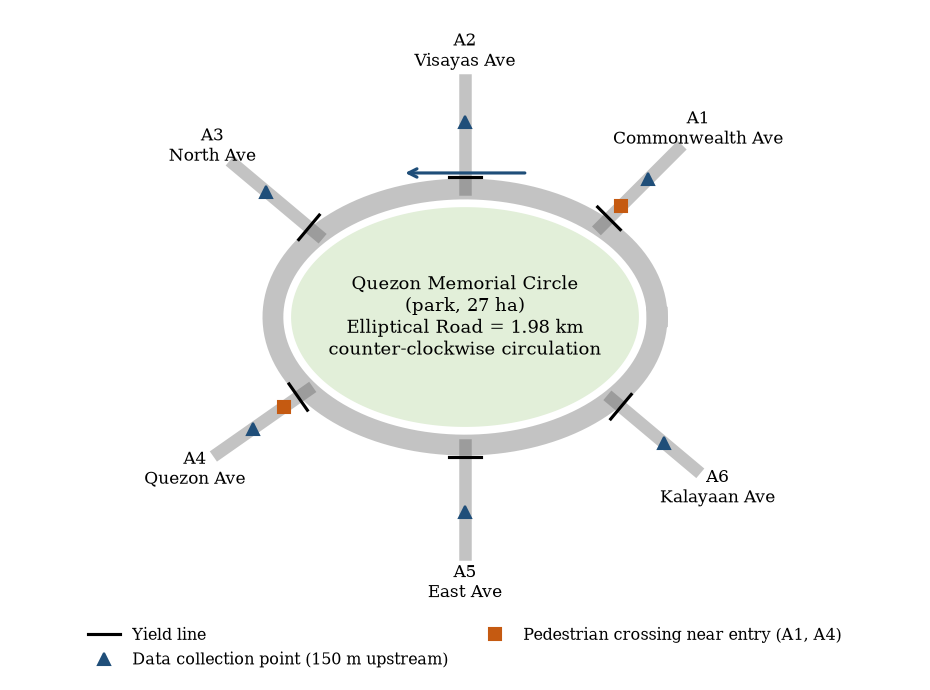

In [19]:
display(Image(f"{OUT}/fig1_study_area.png"))

**Warm-up check (Welch's method)**

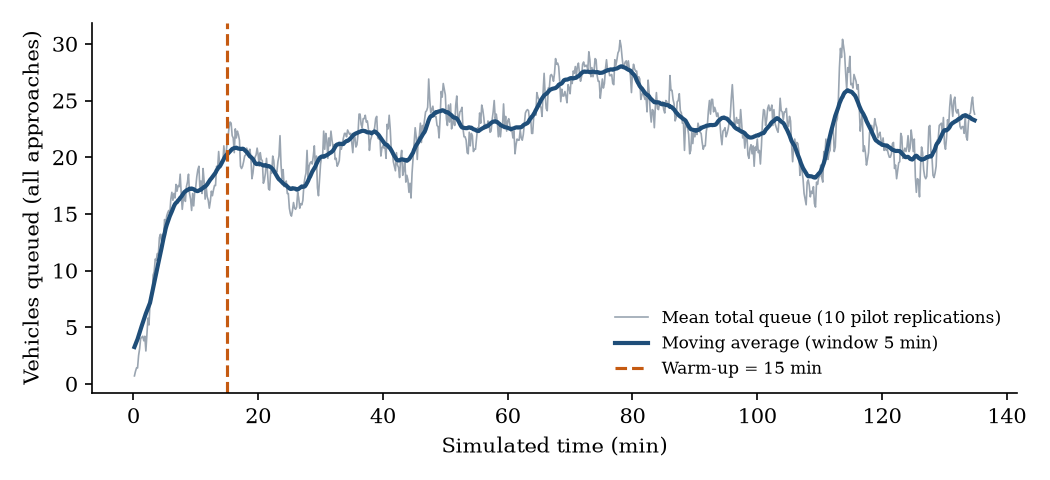

In [20]:
display(Image(f"{OUT}/fig4_welch.png"))

**Model snapshot at t = 60 min**

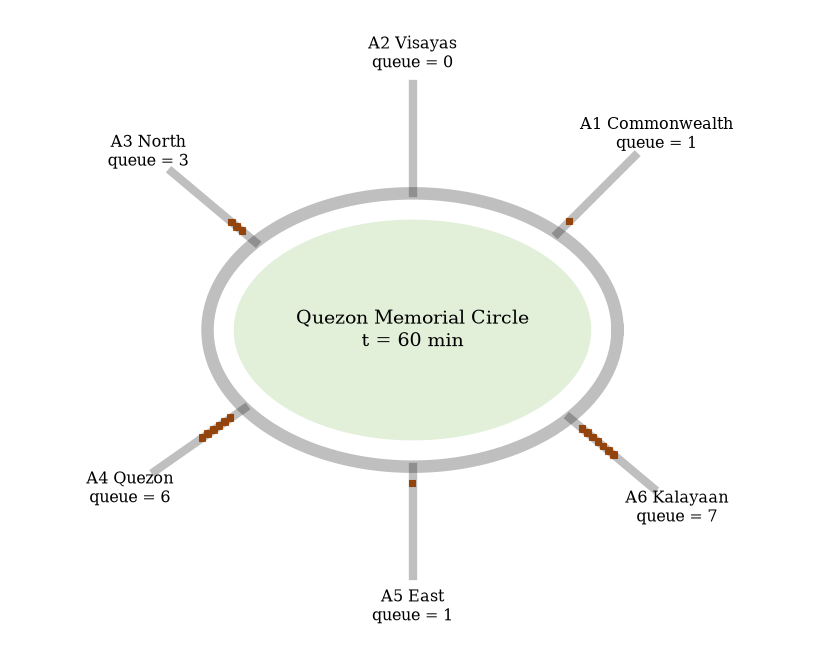

In [21]:
display(Image(f"{OUT}/fig6_snapshot.png"))

**Validation: simulated vs HCM delay**

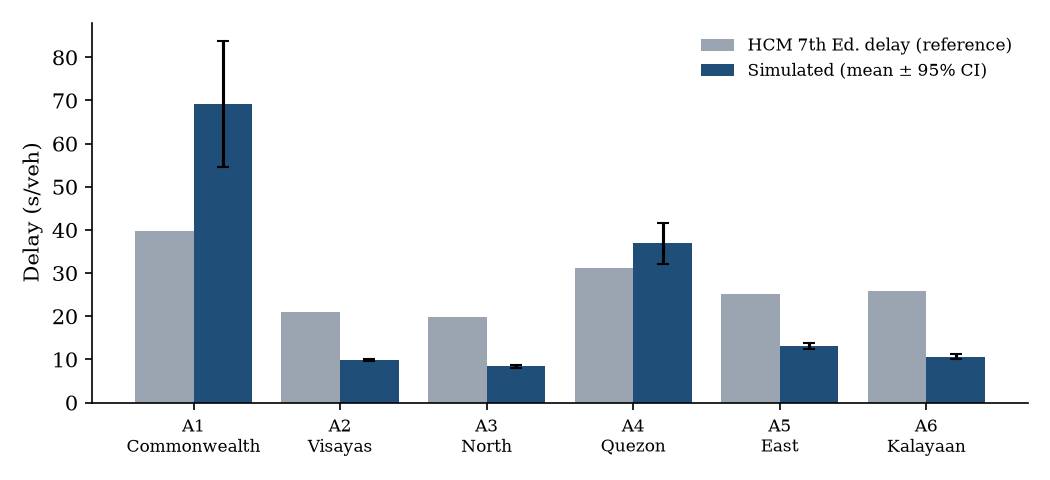

In [22]:
display(Image(f"{OUT}/fig7_validation.png"))

**Queue length over time**

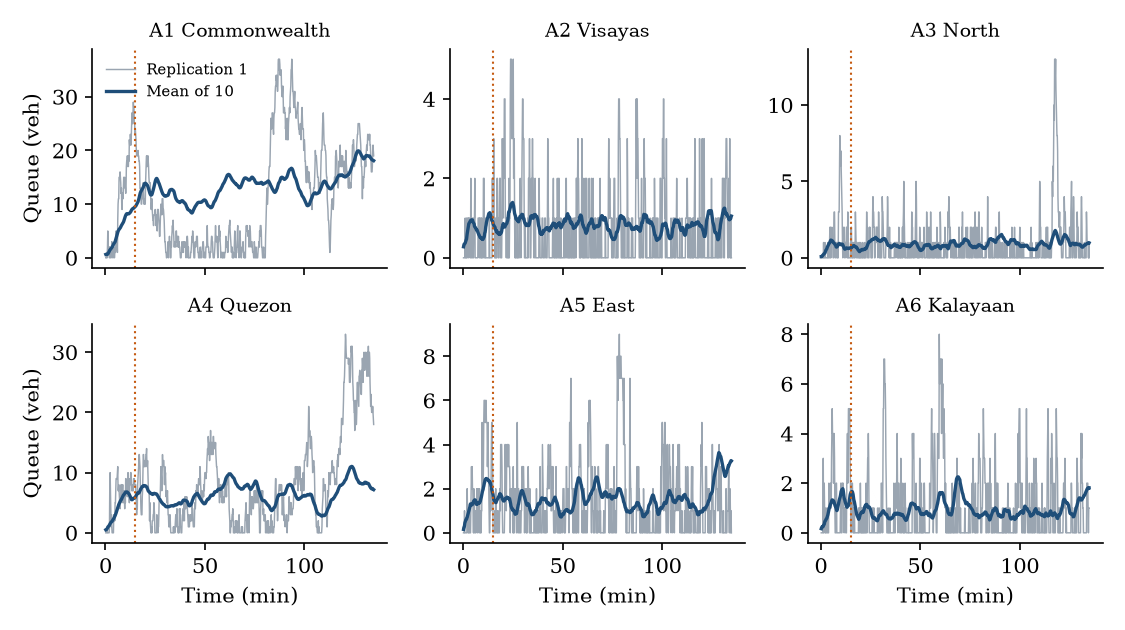

In [23]:
display(Image(f"{OUT}/fig8_queue_time.png"))

**Simulation vs M/M/1 and M/G/1**

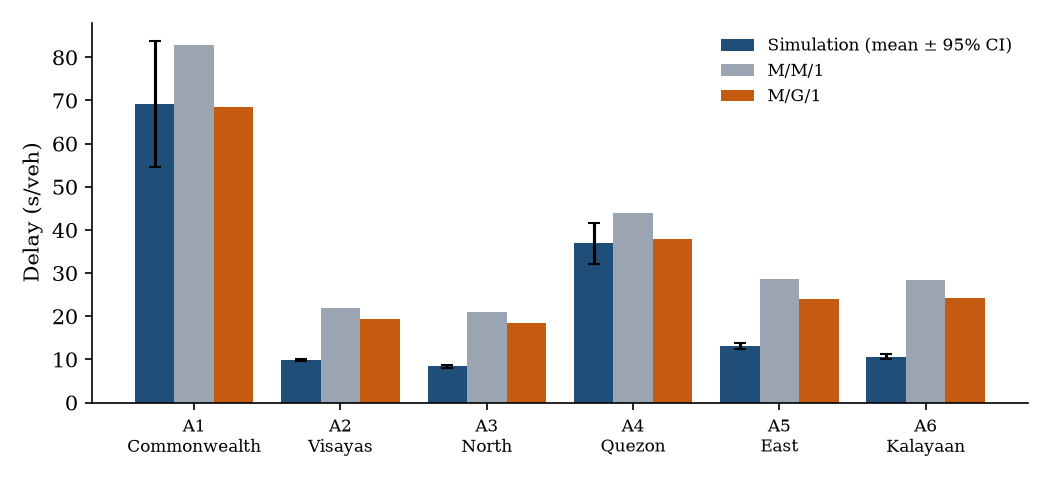

In [24]:
display(Image(f"{OUT}/fig9_delay_baselines.png"))

**Scenario comparison**

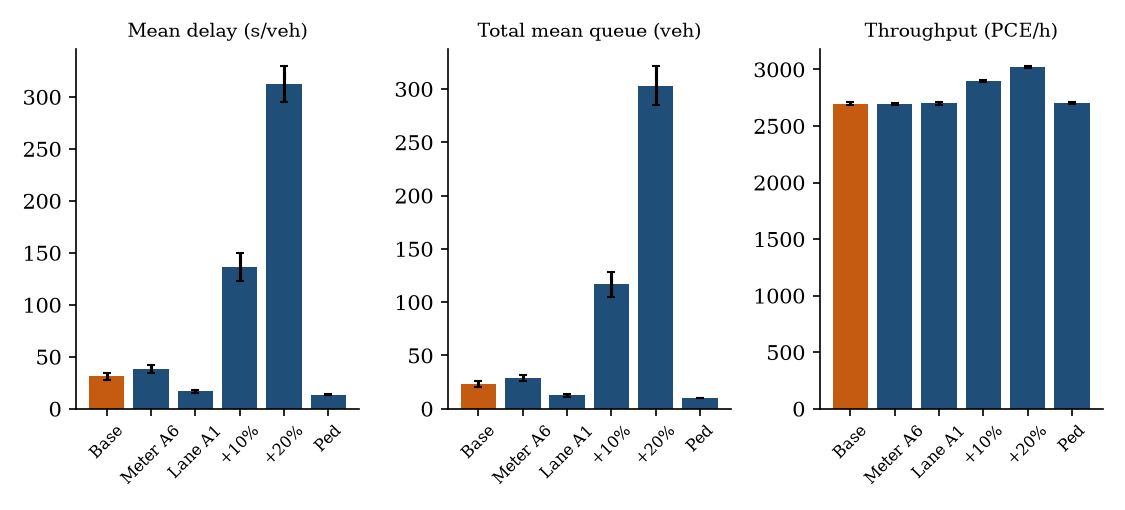

In [25]:
display(Image(f"{OUT}/fig10_scenarios.png"))

**Sensitivity (tornado chart)**

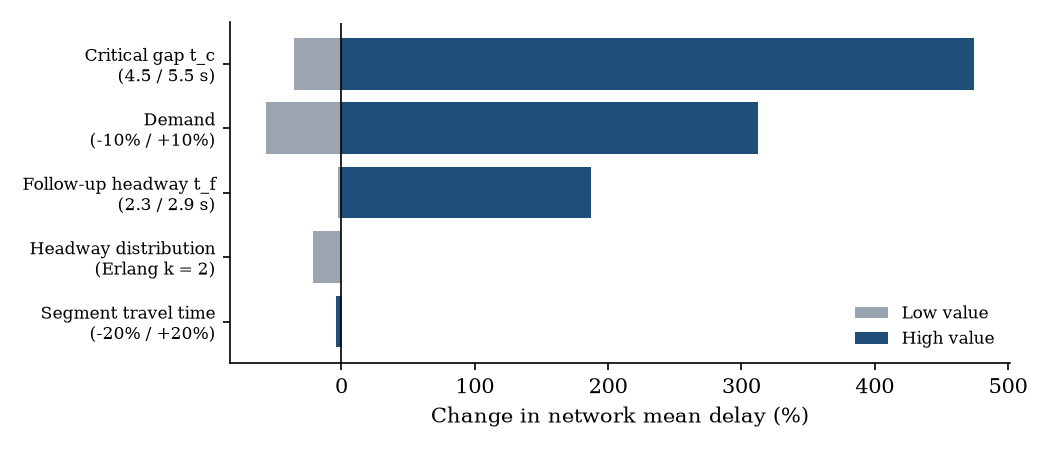

In [26]:
display(Image(f"{OUT}/fig11_sensitivity.png"))

**Input analysis (headways, Raff's method)**

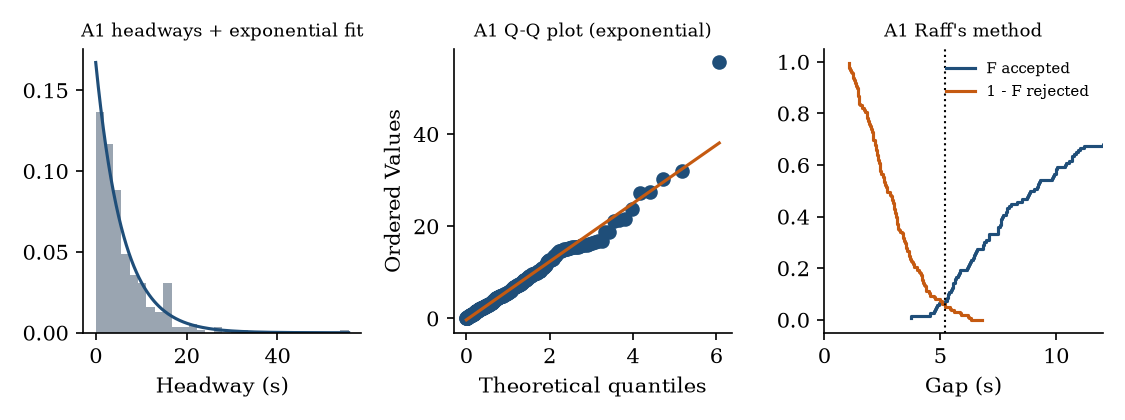

In [27]:
display(Image(f"{OUT}/figC1_inputs.png"))

**Delay by approach and scenario**

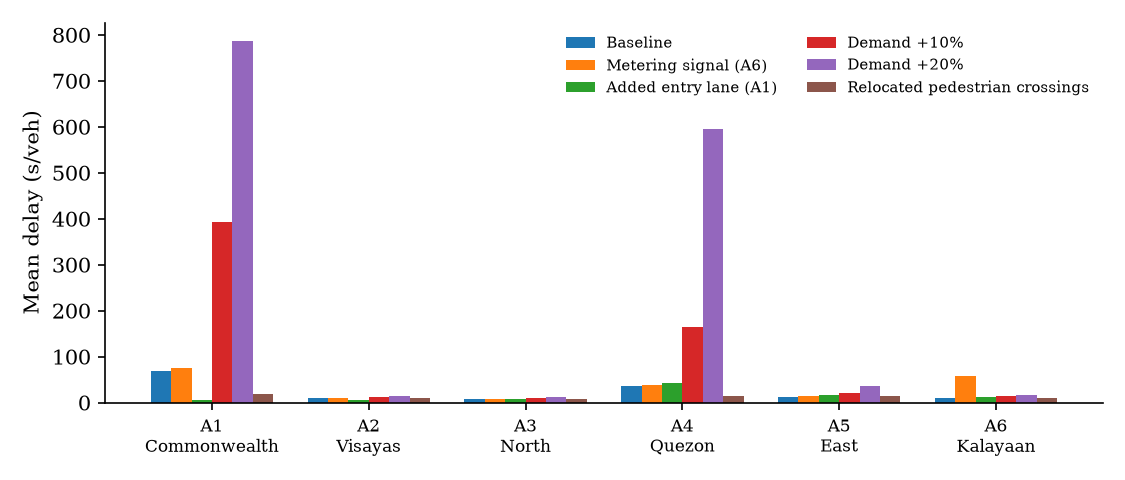

In [28]:
display(Image(f"{OUT}/figC2_scenario_by_approach.png"))

## 8. Summary and limitations

Read the scenario table in 6.6 to rank the options by change in network delay and queue, and use the sensitivity table to see
which inputs matter most. Use these results to support the ranked recommendations in the project documentation.

**Limitations**
- Demand, origin-destination shares and the reference sample are planning-level assumptions, not field data.
- Only the critical entry lane of each approach is modelled; weaving and lane changes inside the circle are simplified.
- Results are for the weekday peak period only.
- Replace `CONFIG` values with field counts and re-run all cells to update every table and figure.